#### 4주차

In [1]:
import numpy as np

perch_length = np.array([8.4, 13.7, 15.0, 16.2, 17.4, 18.0, 18.7, 19.0, 19.6, 20.0, 21.0,
       21.0, 21.0, 21.3, 22.0, 22.0, 22.0, 22.0, 22.0, 22.5, 22.5, 22.7,
       23.0, 23.5, 24.0, 24.0, 24.6, 25.0, 25.6, 26.5, 27.3, 27.5, 27.5,
       27.5, 28.0, 28.7, 30.0, 32.8, 34.5, 35.0, 36.5, 36.0, 37.0, 37.0,
       39.0, 39.0, 39.0, 40.0, 40.0, 40.0, 40.0, 42.0, 43.0, 43.0, 43.5,
       44.0])
perch_weight = np.array([5.9, 32.0, 40.0, 51.5, 70.0, 100.0, 78.0, 80.0, 85.0, 85.0, 110.0,
       115.0, 125.0, 130.0, 120.0, 120.0, 130.0, 135.0, 110.0, 130.0,
       150.0, 145.0, 150.0, 170.0, 225.0, 145.0, 188.0, 180.0, 197.0,
       218.0, 300.0, 260.0, 265.0, 250.0, 250.0, 300.0, 320.0, 514.0,
       556.0, 840.0, 685.0, 700.0, 700.0, 690.0, 900.0, 650.0, 820.0,
       850.0, 900.0, 1015.0, 820.0, 1100.0, 1000.0, 1100.0, 1000.0,
       1000.0])

print (perch_length.shape, perch_weight.shape)

# ─── 중간고사 학습 주석 (원본 코드 수정 없음) ───
# np.array: 파이썬 리스트 등을 NumPy 배열로 변환한다.
# shape: NumPy 배열의 차원별 크기를 보여준다. 예: (42, 1)은 42행 1열.


(56,) (56,)


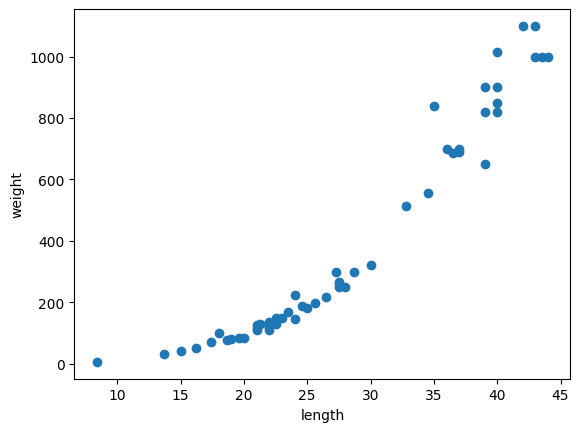

In [2]:
#농어의 산포도
import matplotlib.pyplot as plt

plt.scatter(perch_length, perch_weight)

plt.xlabel('length')
plt.ylabel('weight')

plt.show()

# ─── 중간고사 학습 주석 (원본 코드 수정 없음) ───
# plt.scatter(x, y): 실제 데이터/예측 데이터를 산점도로 나타낸다.
# plt.show(): 지금까지 만든 그래프를 출력한다.


In [3]:
#훈련데이터와 테스트데이터 생성
from sklearn.model_selection import train_test_split

train_input, test_input, train_target, test_target  = train_test_split(perch_length, perch_weight,random_state=42)
#1차원 -> 2차원
train_input = train_input.reshape(-1,1)
test_input = test_input.reshape(-1, 1)
print(train_input.shape, test_input.shape)

# ─── 중간고사 학습 주석 (원본 코드 수정 없음) ───
# train_test_split(X, y, ...): 입력 X와 정답 y를 같은 인덱스로 분할해 훈련·테스트 세트를 만든다.
# random_state: 데이터 분할의 난수 상태를 고정해 반복 실행 시 같은 분할을 재현한다.
# reshape(-1, 1): 1차원 길이 데이터를 한 열을 가진 2차원 입력으로 바꾼다.


(42, 1) (14, 1)


In [4]:
#k최근접 이웃 회귀
from sklearn.neighbors import KNeighborsRegressor
knr = KNeighborsRegressor()
knr.fit(train_input, train_target)
print(knr.score(train_input, train_target))  #훈련데이터의 점수
print(knr.score(test_input, test_target))   #테스트데이터의 점수

# ─── 중간고사 학습 주석 (원본 코드 수정 없음) ───
# KNeighborsRegressor: 가까운 k개 이웃의 타깃 평균을 이용해 수치를 예측한다.
# fit(X, y): 입력 데이터와 정답을 바탕으로 모델을 훈련한다.
# score(X, y): 분류에서는 정확도, 회귀에서는 결정계수 R²를 반환한다.


0.9698823289099254
0.992809406101064


In [5]:
from sklearn.metrics import mean_absolute_error
#테스트데이터에 대한 예측무게
pred = knr.predict(test_input)
pred_target = np.column_stack((pred, test_target)) #예측값과 타겟값을 나란히 출력
print(pred_target)

#테스트 데이터에 대한 평균 절대 오차 구하기
mae = mean_absolute_error(test_target, pred) #타겟과 예측값
print(mae)

# ─── 중간고사 학습 주석 (원본 코드 수정 없음) ───
# predict(X): 학습된 모델이 입력 샘플의 클래스 또는 연속값을 예측한다.
# mean_absolute_error(y_true, y_pred): 각 예측의 절대오차를 평균낸다. 값이 작을수록 평균 오차가 작다.
# np.column_stack: 배열들을 열 방향으로 이어 각 샘플의 특성 열을 구성한다.


[[  60.     5.9]
 [  79.6  100. ]
 [ 248.   250. ]
 [ 122.   130. ]
 [ 136.   130. ]
 [ 847.   820. ]
 [ 311.4  320. ]
 [ 183.4  188. ]
 [ 847.   900. ]
 [ 113.   125. ]
 [1010.  1000. ]
 [  60.    51.5]
 [ 248.   250. ]
 [ 248.   300. ]]
19.157142857142862


### 온라인 4주차에서 보충 — 예측값과 실제값의 산점도 비교

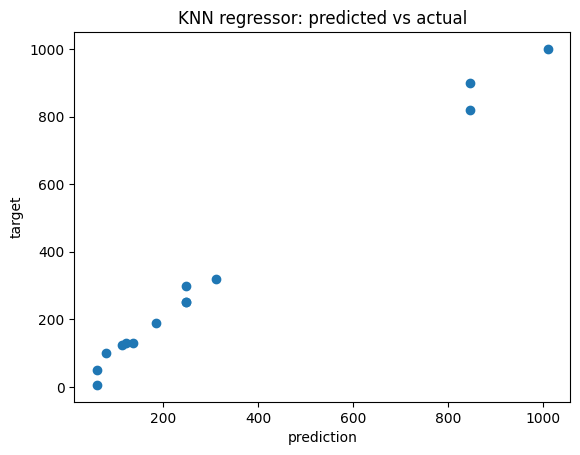

mean_absolute_error: 19.157142857142862


In [6]:
# [온라인 4주차 보충] 오프라인 MAE 계산 직후의 pred와 test_target 사용
# x축: 모델이 예측한 농어 무게, y축: 실제 농어 무게
# 두 값이 비슷할수록 (예측값 ≈ 실제값) 모델의 예측이 잘 맞는 샘플이다.
plt.scatter(pred, test_target)
plt.xlabel('prediction')
plt.ylabel('target')
plt.title('KNN regressor: predicted vs actual')
plt.show()

# MAE는 정답과 예측값 차이의 절댓값을 평균낸 값이다.
print('mean_absolute_error:', mean_absolute_error(test_target, pred))

In [7]:
#과소적합 : 훈련데이터 점수 < 테스트데이터 점수 (현재상황)
#과대적합 : 훈련데이터 점수 > 테스트데이터 점수

#이웃의 수를 5에서 3으로 줄여서 해결하기
#이웃의 수가 많아지면 모든 데이터의 평균값에 가까워지므로 과소적합이 발생
#이웃의 수가 적어지면 국소적인 데이터에 민감하게 반응하므로 과대적합이 발생

**K-최근접 이웃 회귀 그래프**

코드 전용 자료이므로 외부 PNG 참조 대신 바로 아래 산점도 코드 셀을 실행하여 그래프를 확인한다.

In [8]:
knr.n_neighbors = 3 #5->3
knr.fit(train_input, train_target)
print(knr.score(train_input, train_target))  #훈련데이터의 점수
print(knr.score(test_input, test_target))   #테스트데이터의 점수    

# ─── 중간고사 학습 주석 (원본 코드 수정 없음) ───
# n_neighbors: 참고할 최근접 이웃 개수 k. 수를 바꾸면 분류/회귀 결과가 달라질 수 있다.


0.9804899950518966
0.9746459963987609


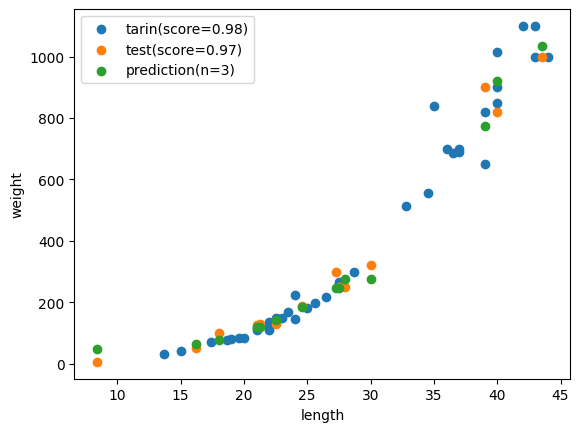

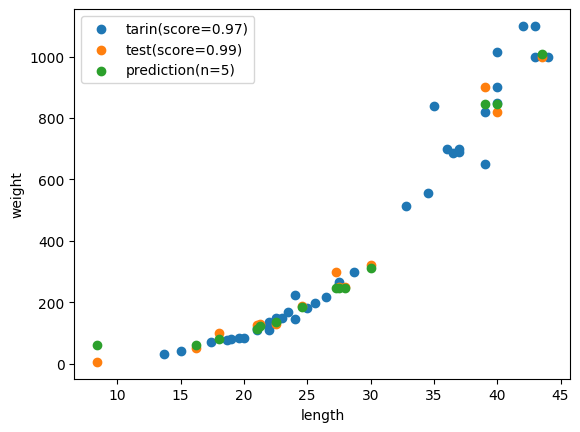

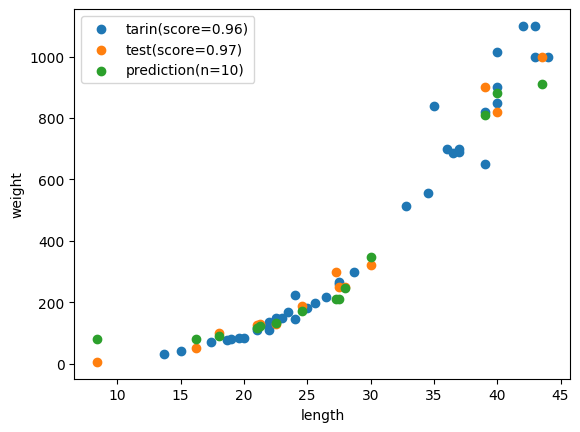

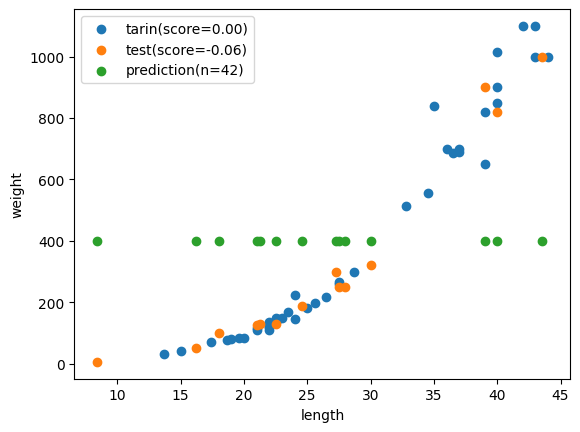

In [9]:
#이웃의 수를 3, 5, 10, 42로 바꾸어 훈련데이터와 테스트데이터의 점수를 확인해보세요.
for n in [3, 5, 10, 42]:
    knr.n_neighbors = n
    knr.fit(train_input, train_target)
    pred = knr.predict(test_input)
    train_score = knr.score(train_input, train_target)
    test_score = knr.score(test_input, test_target)

    #훈련데이터, 테스트테이터, 예측값을 산포도로 확인
    plt.scatter(train_input, train_target,label='tarin(score={score:.2f})'.format(score=train_score))
    plt.scatter(test_input, test_target,label='test(score={score:.2f})'.format(score=test_score))
    plt.scatter(test_input, pred,label='prediction(n={neighbor})'.format(neighbor=n))
    plt.xlabel('length')
    plt.ylabel('weight')
    plt.legend()
    plt.show()



[1033.33333333]


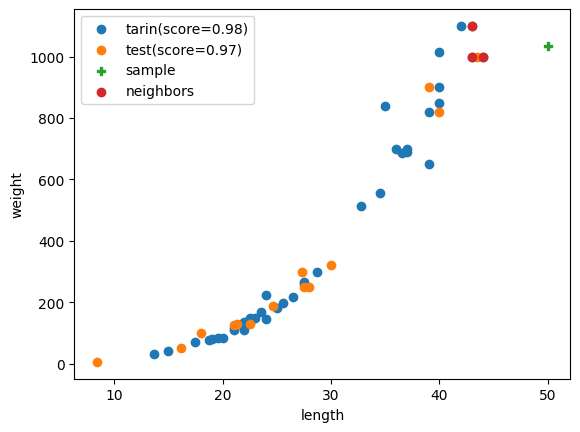

In [10]:
#길이가 50인 농어의 무게예측
sample = np.array([[50]])
knr.n_neighbors = 3
knr.fit(train_input, train_target)
train_score = knr.score(train_input, train_target)
test_score = knr.score(test_input, test_target)
pred = knr.predict(sample)
print(pred)
#샘플의 이웃 확인
dist,idx = knr.kneighbors(sample)
#샘플과 이웃 산포도
plt.scatter(train_input, train_target,label='tarin(score={score:.2f})'.format(score=train_score))
plt.scatter(test_input, test_target,label='test(score={score:.2f})'.format(score=test_score))
plt.scatter(sample,pred,marker='P',label='sample')
plt.scatter(train_input[idx], train_target[idx],label='neighbors')
plt.xlabel('length')
plt.ylabel('weight')
plt.legend()
plt.show()

# ─── 중간고사 학습 주석 (원본 코드 수정 없음) ───
# kneighbors(X): 가까운 이웃까지의 거리와 훈련 세트 내 인덱스를 돌려준다.


### 7주차

[1033.33333333]


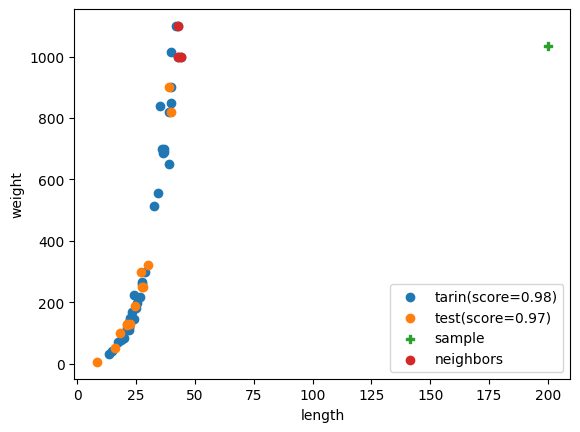

In [11]:
#길이가 200인 농어의 무게예측(학습 범위 밖 외삽 예제)
sample = np.array([[200]])
knr.n_neighbors = 3
knr.fit(train_input, train_target)
train_score = knr.score(train_input, train_target)
test_score = knr.score(test_input, test_target)
pred = knr.predict(sample)
print(pred)
#샘플의 이웃 확인
dist,idx = knr.kneighbors(sample)
#샘플과 이웃 산포도
plt.scatter(train_input, train_target,label='tarin(score={score:.2f})'.format(score=train_score))
plt.scatter(test_input, test_target,label='test(score={score:.2f})'.format(score=test_score))
plt.scatter(sample,pred,marker='P',label='sample')
plt.scatter(train_input[idx], train_target[idx],label='neighbors')
plt.xlabel('length')
plt.ylabel('weight')
plt.legend()
plt.show()

# ─── 중간고사 학습 주석 (수정본) ───
# [범위 설명] 이 셀 앞의 원본 Markdown에는 7주차라고 적혀 있으나, 내용은 KNN 회귀의 외삽 한계(200cm 예측)를 보여준다. 시험 핵심은 5장 선형회귀까지이며 추가적인 7주차 단원으로 확장하지 않는다.
# [오류 수정] 예제 입력이 200cm이므로 잘못 적힌 50cm 설명을 바로잡았습니다.
